In [1]:
pip install numpy pandas matplotlib scikit-learn joblib

Dataset Shape: (48842, 15)

First Five Rows:
   age  workclass  fnlwgt     education  education-num      marital-status  \
0   25    Private  226802          11th              7       Never-married   
1   38    Private   89814       HS-grad              9  Married-civ-spouse   
2   28  Local-gov  336951    Assoc-acdm             12  Married-civ-spouse   
3   44    Private  160323  Some-college             10  Married-civ-spouse   
4   18        NaN  103497  Some-college             10       Never-married   

          occupation relationship   race     sex  capital-gain  capital-loss  \
0  Machine-op-inspct    Own-child  Black    Male             0             0   
1    Farming-fishing      Husband  White    Male             0             0   
2    Protective-serv      Husband  White    Male             0             0   
3  Machine-op-inspct      Husband  Black    Male          7688             0   
4                NaN    Own-child  White  Female             0             0   

   ho

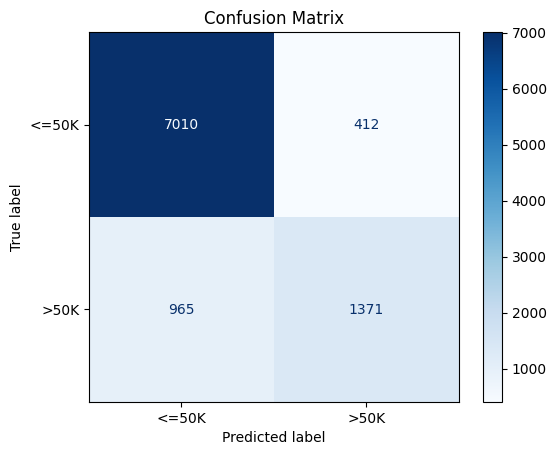


Misclassified Samples: 1377

First 10 Misclassified Samples:
       age         workclass  fnlwgt     education  education-num  \
10557   34         Local-gov  108247  Some-college             10   
11572   33           Private  158438  Some-college             10   
2967    59           Private  192845       HS-grad              9   
29443   34           Private  250724     Bachelors             13   
36457   63  Self-emp-not-inc  289741       Masters             14   
46086   62  Self-emp-not-inc   75478     Bachelors             13   
15661   56  Self-emp-not-inc  111385     Bachelors             13   
34387   31         State-gov  124020    Assoc-acdm             12   
45384   47           Private  186534       HS-grad              9   
46571   47           Private  140644       HS-grad              9   

           marital-status         occupation relationship   race  \
10557  Married-civ-spouse    Exec-managerial      Husband  White   
11572  Married-civ-spouse       Craft-repa

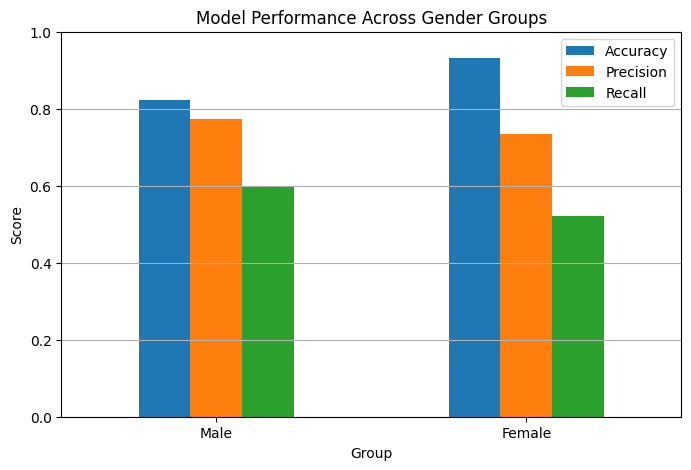


THRESHOLD COMPARISON
   Threshold  Precision    Recall  F1 Score
0        0.3   0.596651  0.839041  0.697385
1        0.4   0.702037  0.708048  0.705030
2        0.5   0.768929  0.586901  0.665696
3        0.6   0.834752  0.503853  0.628404


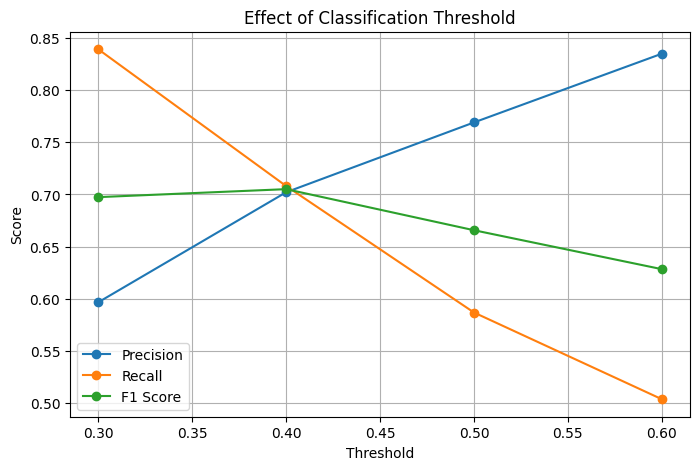


ORIGINAL VS MODIFIED THRESHOLD
Original Precision: 0.7689287717330342
Modified Precision: 0.702037351443124
Original Recall: 0.5869006849315068
Modified Recall: 0.7080479452054794

FAIRNESS BEFORE INTERVENTION
    Group  Samples  Accuracy  Precision    Recall  Positive Prediction Rate
0    Male     6526  0.823322   0.774110  0.598000                  0.236745
1  Female     3232  0.930693   0.735294  0.520833                  0.073639

FAIRNESS AFTER INTERVENTION
    Group  Samples  Accuracy  Precision    Recall  Positive Prediction Rate
0    Male     6526  0.824088    0.70944  0.721500                  0.311676
1  Female     3232  0.926980    0.65528  0.627976                  0.099629

Model and metadata saved successfully.

FINAL SUMMARY
-----------------------------
Dataset: Adult Census Income
Selected Model: Random Forest
Training Samples: 39032
Testing Samples: 9758
Best CV ROC-AUC: 0.9166833993123553
Test Accuracy: 0.8588850174216028
Test ROC-AUC: 0.9142675145716364
Misclassifi

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import json
import sklearn

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)

# 1. Load Dataset
data = fetch_openml(name="adult", version=2, as_frame=True)

df = data.frame.copy()

print("Dataset Shape:", df.shape)
print("\nFirst Five Rows:")
print(df.head())

# 2. Identify Target and Sensitive Attribute
target = data.target.name
sensitive_attribute = "sex"

print("\nTarget Variable:", target)
print("Sensitive Attribute:", sensitive_attribute)

# 3. Handle Missing and Inconsistent Values
df = df.replace("?", np.nan)
df = df.drop_duplicates()
df[target] = df[target].astype(str).str.strip().str.rstrip(".")

# 4. Separate Features and Target
y = (df[target] == ">50K").astype(int)

sensitive = df[sensitive_attribute].copy()

X = df.drop(columns=[target, sensitive_attribute])

print("\nFeature Shape:", X.shape)
print("\nMissing Values:")
print(X.isnull().sum().sum())

# 5. Train-Test Split
X_train, X_test, y_train, y_test, s_train, s_test = train_test_split(
    X, y, sensitive,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 6. Identify Numerical and Categorical Features
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# 7. Define Preprocessing Operations
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 8. Create Preprocessing Pipeline
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

# 9. Define Candidate Models
models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=42),
        {"model__C": [0.1, 1, 10]}
    ),

    "Random Forest": (
        RandomForestClassifier(random_state=42, n_jobs=-1),
        {
            "model__n_estimators": [100],
            "model__max_depth": [10, 20],
            "model__min_samples_leaf": [1, 5]
        }
    )
}

# 10. Model Selection and Hyperparameter Tuning
results = []
best_model = None
best_score = -1
best_name = ""

for name, (classifier, parameters) in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", classifier)
    ])

    grid = GridSearchCV(
        pipeline,
        parameters,
        cv=5,
        scoring="roc_auc",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    print("\nModel:", name)
    print("Best Parameters:", grid.best_params_)
    print("Cross Validation ROC-AUC:", grid.best_score_)

    results.append([
        name,
        grid.best_score_,
        grid.best_params_
    ])

    if grid.best_score_ > best_score:
        best_score = grid.best_score_
        best_model = grid.best_estimator_
        best_name = name

print("\nSelected Model:", best_name)

# 11. Evaluate Final Model on Test Data
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("\nFINAL MODEL PERFORMANCE")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 12. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["<=50K", ">50K"]
).plot(cmap="Blues")

plt.title("Confusion Matrix")
plt.show()

# 13. Error Analysis
errors = X_test.copy()
errors["Actual"] = y_test
errors["Predicted"] = y_pred

misclassified = errors[
    errors["Actual"] != errors["Predicted"]
]

print("\nMisclassified Samples:", len(misclassified))
print("\nFirst 10 Misclassified Samples:")
print(misclassified.head(10))

# 14. Subgroup Fairness Evaluation
def fairness_audit(actual, predicted, groups):

    audit = pd.DataFrame({
        "Actual": np.asarray(actual),
        "Predicted": np.asarray(predicted),
        "Group": np.asarray(groups)
    })

    records = []

    for group in audit["Group"].dropna().unique():

        subset = audit[audit["Group"] == group]

        records.append({
            "Group": group,
            "Samples": len(subset),
            "Accuracy": accuracy_score(
                subset["Actual"], subset["Predicted"]
            ),
            "Precision": precision_score(
                subset["Actual"], subset["Predicted"],
                zero_division=0
            ),
            "Recall": recall_score(
                subset["Actual"], subset["Predicted"],
                zero_division=0
            ),
            "Positive Prediction Rate": subset["Predicted"].mean()
        })

    return pd.DataFrame(records)


print("\nFAIRNESS AUDIT - SEX")
fairness_results = fairness_audit(
    y_test, y_pred, s_test
)

print(fairness_results)

# 15. Visualize Subgroup Performance
fairness_results.set_index("Group")[
    ["Accuracy", "Precision", "Recall"]
].plot(kind="bar", figsize=(8, 5))

plt.title("Model Performance Across Gender Groups")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

# 16. Threshold Intervention
thresholds = [0.3, 0.4, 0.5, 0.6]

threshold_results = []

for threshold in thresholds:

    predictions = (y_prob >= threshold).astype(int)

    threshold_results.append([
        threshold,
        precision_score(y_test, predictions, zero_division=0),
        recall_score(y_test, predictions, zero_division=0),
        f1_score(y_test, predictions, zero_division=0)
    ])

threshold_df = pd.DataFrame(
    threshold_results,
    columns=["Threshold", "Precision", "Recall", "F1 Score"]
)

print("\nTHRESHOLD COMPARISON")
print(threshold_df)

# 17. Plot Threshold Performance
threshold_df.set_index("Threshold").plot(
    marker="o", figsize=(8, 5)
)

plt.title("Effect of Classification Threshold")
plt.ylabel("Score")
plt.grid()
plt.show()

# 18. Apply Modified Threshold
new_threshold = 0.4
modified_pred = (y_prob >= new_threshold).astype(int)

print("\nORIGINAL VS MODIFIED THRESHOLD")
print("Original Precision:", precision_score(y_test, y_pred))
print("Modified Precision:", precision_score(
    y_test, modified_pred, zero_division=0
))

print("Original Recall:", recall_score(y_test, y_pred))
print("Modified Recall:", recall_score(
    y_test, modified_pred, zero_division=0
))

# 19. Compare Fairness Before and After Intervention
print("\nFAIRNESS BEFORE INTERVENTION")
print(fairness_audit(y_test, y_pred, s_test))

print("\nFAIRNESS AFTER INTERVENTION")
print(fairness_audit(y_test, modified_pred, s_test))

# 20. Save Final Model
joblib.dump(best_model, "responsible_ml_model.pkl")

# 21. Save Metadata for Reproducibility
metadata = {
    "dataset": "Adult Census Income",
    "selected_model": best_name,
    "best_cross_validation_roc_auc": float(best_score),
    "best_parameters": {
        key: str(value)
        for key, value in best_model.named_steps["model"].get_params().items()
        if key in (
            "C", "n_estimators",
            "max_depth", "min_samples_leaf"
        )
    },
    "random_state": 42,
    "test_size": 0.2,
    "threshold": new_threshold,
    "sklearn_version": sklearn.__version__
}

with open("model_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("\nModel and metadata saved successfully.")

# 22. Final Summary
print("\nFINAL SUMMARY")
print("-----------------------------")
print("Dataset:", "Adult Census Income")
print("Selected Model:", best_name)
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Best CV ROC-AUC:", best_score)
print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test ROC-AUC:", roc_auc_score(y_test, y_prob))
print("Misclassified Samples:", len(misclassified))
print("Fairness Groups:", list(s_test.unique()))
print("Model File: responsible_ml_model.pkl")
print("Metadata File: model_metadata.json")
